<a href="https://colab.research.google.com/github/Endoefa/ovo/blob/main/Tutorial_Five.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## UFMFRR-15-M Machine Vision Tutorial
# Unit 5 - Image Convolution

In [23]:
import cv2
import matplotlib.pyplot as plt
from google.colab.patches import cv2_imshow
import numpy as np

import skimage.util as util
from scipy import ndimage
from skimage.exposure import rescale_intensity

In [24]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# The function for convolving a source image with a kernel

In [25]:
def convolve(img, kernel):
    (sh, sw) = img.shape[:2]
    (kh, kw) = kernel.shape[:2]

    # 用复制边缘像素的方式填充图像，避免卷积后尺寸缩小
    pad = (kw - 1) // 2
    img = cv2.copyMakeBorder(
        img, pad, pad, pad, pad, cv2.BORDER_REPLICATE
    )

    output = np.zeros((sh, sw), dtype="float32")

    for y in np.arange(pad, sh + pad):
        for x in np.arange(pad, sw + pad):
            # 取出与卷积核同样大小的局部图像区域
            roi = img[y - pad:y + pad + 1, x - pad:x + pad + 1]

            # 局部区域与卷积核逐元素相乘后求和，作为输出像素值
            # 这里没有翻转卷积核；对于均值核这样的对称核，结果相同
            k = (roi * kernel).sum()
            output[y - pad, x - pad] = k

    # 将结果映射到可显示的像素范围，再转为 8 位图像
    output = rescale_intensity(output, in_range=(0, 255))
    output = (255 * output).astype("uint8")

    return output

# Add salt & pepper noise/Gaussian noise to an image

* Read an image and conver to greyscale

In [26]:
rose = cv2.imread('/content/drive/MyDrive/Colab/rose.jpg')

# cv2.imread 读入的是 BGR 顺序，因此这里使用 COLOR_BGR2GRAY
grey = cv2.cvtColor(rose, cv2.COLOR_BGR2GRAY)

* Add salt and pepper noise

In [27]:
# s&p 表示 salt-and-pepper（椒盐）噪声
# random_noise 的结果是 0～1 之间的浮点数
grey_sp = util.random_noise(grey, 's&p', clip=True)

* Results returned was scaled between 0 and 1. Change it to 0 and 255

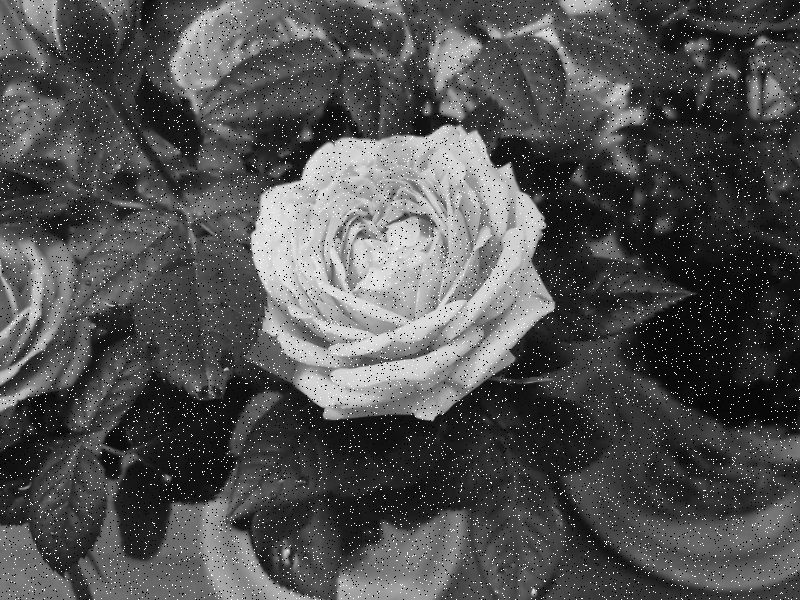

In [28]:
# 转回 0～255 的像素范围和 uint8 格式，方便后续 OpenCV 处理
grey_sp = (grey_sp * 255).astype(np.uint8)
cv2_imshow(grey_sp)

* Add Gaussian noise

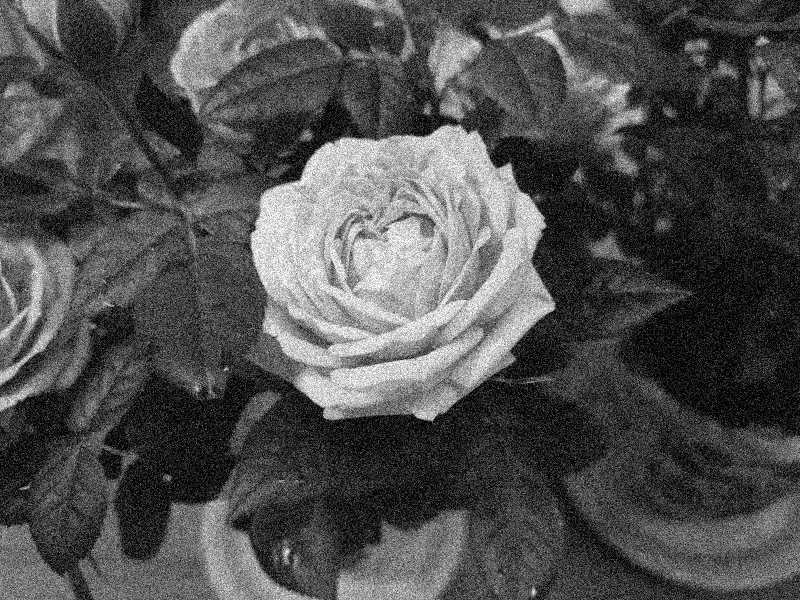

In [29]:
# gaussian 表示给图像添加高斯分布的随机噪声
grey_gauss = util.random_noise(grey, 'gaussian', clip=True)
grey_gauss = (grey_gauss * 255).astype(np.uint8)
cv2_imshow(grey_gauss)

# Convolution

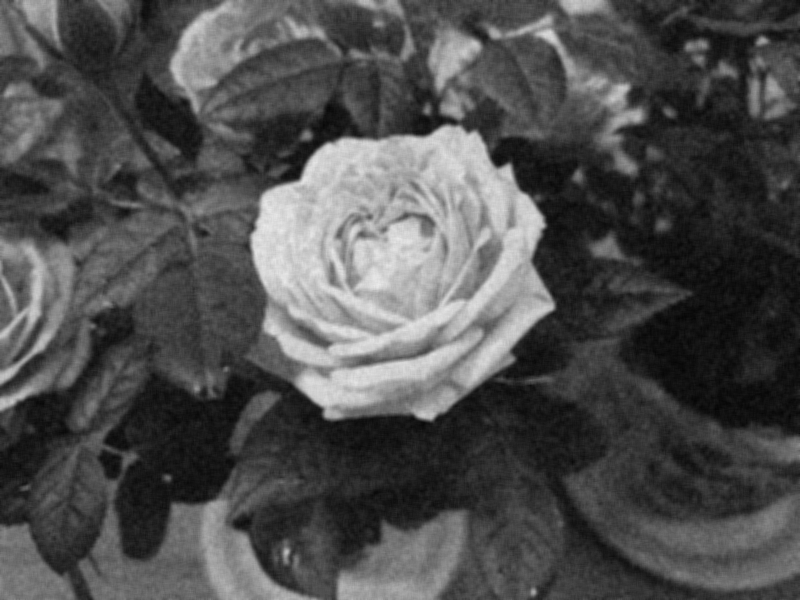

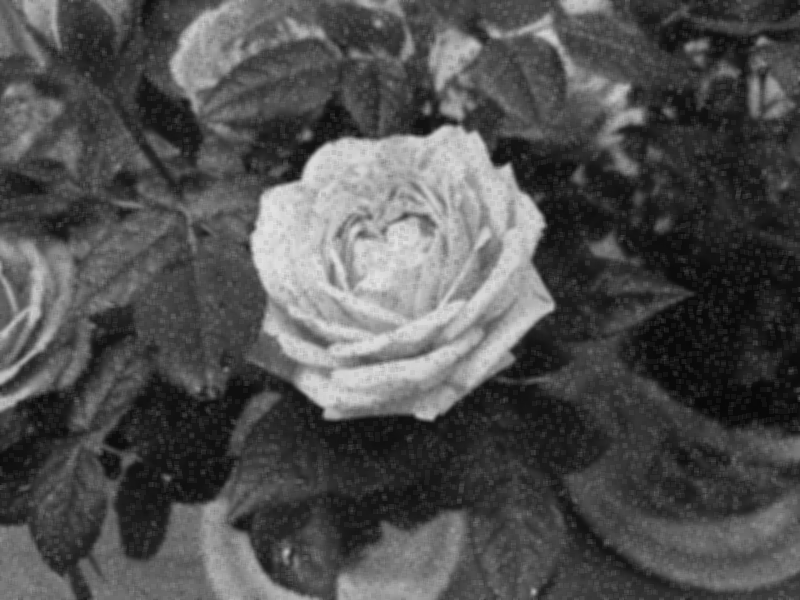

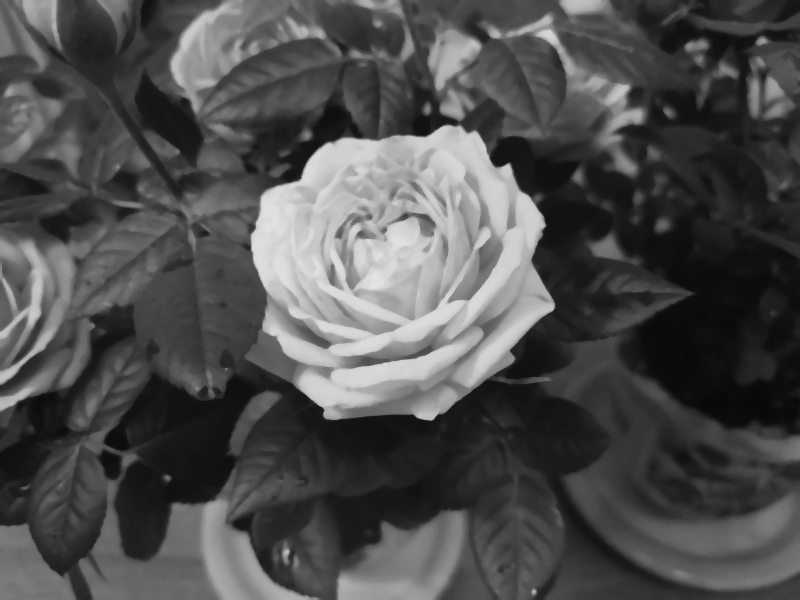

In [30]:
# 3×3 均值滤波核：邻域内 9 个像素的权重相同
kernel_avg = 1 / (3 * 3) * np.array(
    ([1, 1, 1],
     [1, 1, 1],
     [1, 1, 1]),
    dtype="int"
)

# 5×5 均值滤波核：邻域内 25 个像素的权重相同
kernel_avg2 = np.ones((5, 5)) / 25

# 均值滤波能平滑高斯噪声，但也可能模糊图像细节
convoleOutput = convolve(grey_gauss, kernel_avg2)
cv2_imshow(convoleOutput)

# 用同一个均值滤波核处理椒盐噪声
convoleOutput = convolve(grey_sp, kernel_avg2)
cv2_imshow(convoleOutput)

# 中值滤波用邻域像素的中位数替换中心像素，通常更适合去除椒盐噪声
med_denoised = ndimage.median_filter(grey_sp, 5)
cv2_imshow(med_denoised)

# Extension - edge and corner detection operator

* Canny edge detector

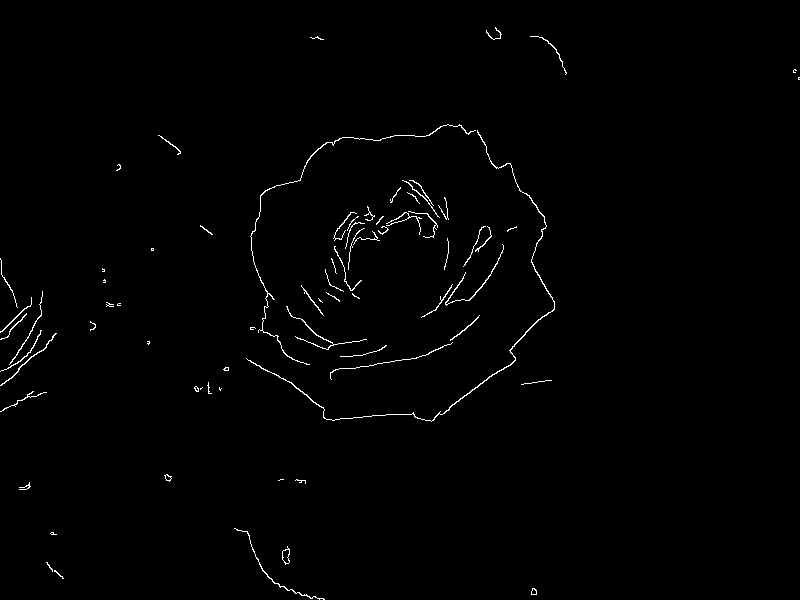

In [31]:
# Canny 用低、高两个阈值判断边缘，并通过滞后过程连接边缘
edges = cv2.Canny(np.uint8(grey),200,400)  # 200, 400 here are the double thresholds used for hysteresis analysis
cv2_imshow(edges)

* Harris corner detector

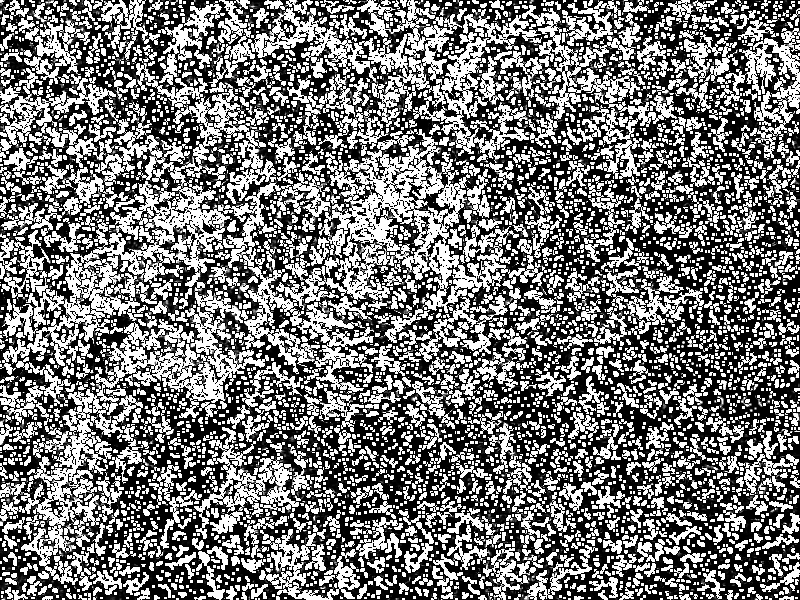

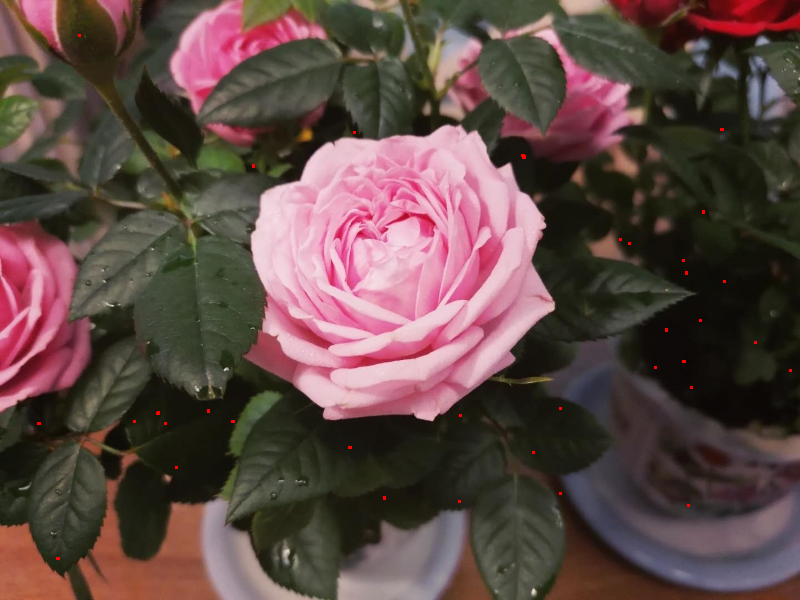

In [32]:
grey = np.float32(grey_sp)
dst = cv2.cornerHarris(grey, blockSize=3, ksize=1, k=0.06)   # Harris 角点检测：blockSize 是邻域大小，ksize 是 Sobel 导数核大小，k 是检测公式中的参数
# blockSize - the size of neighbourhood considered for corner detection,
# ksize - Aperture parameter of Sobel derivative used,
# k - Harris detector free parameter in the equation. Normally a smaller k gives you more corners.
cv2_imshow(dst)
# result is dilated for marking the corners, not important
dst = cv2.dilate(dst,None)
# Threshold for an optimal value, it may vary depending on the image.
# 只把响应值较强的区域标成红色
rose[dst>0.5*dst.max()] = [0,0,255]
cv2_imshow(rose)